# SVM – Dự đoán bệnh tim (Đề tài 46) · TV3
**Nhiệm vụ:** So sánh Linear kernel và RBF kernel, tune tham số C (và gamma cho RBF), phân tích tính tuyến tính / phi tuyến của dữ liệu.

**Sản phẩm:** Notebook + ROC + dictionary kết quả (+ `y_pred`, `y_score` trên Test cho TV5).

**Quy ước chung:** `RANDOM_STATE = 42` · `StratifiedKFold(5, shuffle=True, random_state=42)` · tiêu chí chọn tham số: **ROC-AUC** · tiền xử lý nằm trong `Pipeline` (fit trên từng fold, không leakage) · không dùng Test để tune.

## 0. Giải nén và load dữ liệu chung

In [3]:
!unzip -oq data.zip
!pip install -q -r data/requirements.txt

In [4]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

RANDOM_STATE = 42
OUT_DIR = "outputs_svm"
os.makedirs(OUT_DIR, exist_ok=True)

# Load RAW data (nguồn chính cho CV và Test)
X_train = pd.read_csv("data/X_train_raw.csv")
X_test  = pd.read_csv("data/X_test_raw.csv")
y_train = np.load("data/y_train.npy")
y_test  = np.load("data/y_test.npy")
feature_names = np.load("data/feature_names.npy", allow_pickle=True)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (237, 13) | X_test: (60, 13)
y_train: (237,) | y_test: (60,)


## 1. Khám phá nhanh dữ liệu

In [5]:
display(X_train.head())
print("Missing values:", int(X_train.isna().sum().sum()))
print("Phân bố nhãn train:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Phân bố nhãn test :", dict(zip(*np.unique(y_test, return_counts=True))))
display(X_train.describe().T)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,54.0,1.0,4.0,124.0,266.0,0.0,2.0,109.0,1.0,2.2,2.0,1.0,7.0
1,46.0,1.0,2.0,101.0,197.0,1.0,0.0,156.0,0.0,0.0,1.0,0.0,7.0
2,43.0,1.0,3.0,130.0,315.0,0.0,0.0,162.0,0.0,1.9,1.0,1.0,3.0
3,47.0,1.0,3.0,138.0,257.0,0.0,2.0,156.0,0.0,0.0,1.0,0.0,3.0
4,58.0,1.0,4.0,150.0,270.0,0.0,2.0,111.0,1.0,0.8,1.0,0.0,7.0


Missing values: 0
Phân bố nhãn train: {np.int64(0): np.int64(128), np.int64(1): np.int64(109)}
Phân bố nhãn test : {np.int64(0): np.int64(32), np.int64(1): np.int64(28)}


,count,mean,std,min,25%,50%,75%,max
age,237.0,54.772152,9.032356,34.0,48.0,56.0,62.0,77.0
sex,237.0,0.675105,0.469327,0.0,0.0,1.0,1.0,1.0
cp,237.0,3.185654,0.956315,1.0,3.0,3.0,4.0,4.0
trestbps,237.0,132.270042,17.915848,94.0,120.0,130.0,140.0,200.0
chol,237.0,249.409283,53.162339,126.0,212.0,243.0,277.0,564.0
fbs,237.0,0.168776,0.375347,0.0,0.0,0.0,0.0,1.0
restecg,237.0,0.983122,0.995610,0.0,0.0,0.0,2.0,2.0
thalach,237.0,149.843882,22.397528,88.0,136.0,152.0,166.0,195.0
exang,237.0,0.345992,0.476697,0.0,0.0,0.0,1.0,1.0
oldpeak,237.0,1.061603,1.179594,0.0,0.0,0.8,1.8,6.2


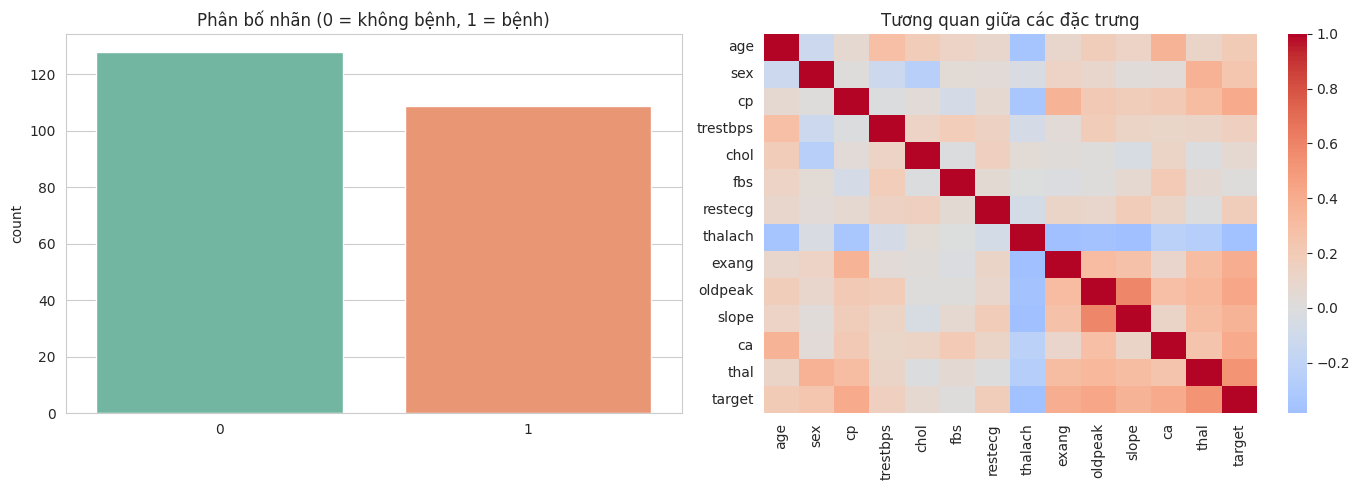

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x=y_train, ax=ax[0], palette="Set2")
ax[0].set_title("Phân bố nhãn (0 = không bệnh, 1 = bệnh)")
sns.heatmap(X_train.assign(target=y_train).corr(), cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Tương quan giữa các đặc trưng")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/svm_eda.png", dpi=150)
plt.show()

## 2. Tiền xử lý trong Pipeline (tránh data leakage)
Phân nhóm cột tự động theo số giá trị khác nhau:
- **Số liên tục** (>10 giá trị): impute median + `StandardScaler`
- **Nhị phân** (≤2 giá trị): giữ nguyên
- **Phân loại nhiều mức** (còn lại): `OneHotEncoder`

SVM nhạy với thang đo nên bắt buộc phải scale, và scaler được fit lại trên phần train của từng fold.

In [7]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 10]
bin_cols = [c for c in X_train.columns if X_train[c].nunique() <= 2]
cat_cols = [c for c in X_train.columns if c not in num_cols + bin_cols]
print("Số liên tục    :", num_cols)
print("Nhị phân       :", bin_cols)
print("Phân loại (OHE):", cat_cols)

def make_pipe(kernel="rbf"):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
        ("bin", SimpleImputer(strategy="most_frequent"), bin_cols),
    ])
    return Pipeline([("pre", pre),
                     ("svc", SVC(kernel=kernel, random_state=RANDOM_STATE))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1": "f1", "ROC_AUC": "roc_auc"}   # roc_auc dùng decision_function của SVC

def cv_summary(estimator):
    res = cross_validate(estimator, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    return {m: (res[f"test_{m}"].mean(), res[f"test_{m}"].std()) for m in SCORING}, res

Số liên tục    : ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Nhị phân       : ['sex', 'fbs', 'exang']
Phân loại (OHE): ['cp', 'restecg', 'slope', 'ca', 'thal']


## 3. Baseline: SVM tham số mặc định (Linear vs RBF)

In [8]:
rows = []
for k in ["linear", "rbf"]:
    s, _ = cv_summary(make_pipe(k))
    rows.append({"Kernel": k, **{m: f"{s[m][0]:.4f} ± {s[m][1]:.4f}" for m in SCORING}})
baseline_df = pd.DataFrame(rows).set_index("Kernel")
display(baseline_df)

,Accuracy,Precision,Recall,F1,ROC_AUC
Kernel,,,,,
linear,0.8055 ± 0.0504,0.8263 ± 0.0832,0.7511 ± 0.1100,0.7780 ± 0.0575,0.8950 ± 0.0588
rbf,0.8270 ± 0.0607,0.8438 ± 0.0722,0.7697 ± 0.0984,0.8017 ± 0.0714,0.8842 ± 0.0684


## 4. Tune tham số bằng GridSearchCV (tiêu chí ROC-AUC, 5-Fold Stratified CV)
- **Linear:** tune `C`
- **RBF:** tune `C` và `gamma` (tổng cộng không quá 2–3 tham số)

In [9]:
# ---- Linear: tune C ----
C_lin = np.logspace(-3, 2, 11)
grid_lin = GridSearchCV(make_pipe("linear"), {"svc__C": C_lin},
                        scoring="roc_auc", cv=cv, n_jobs=-1, refit=True, return_train_score=True)
grid_lin.fit(X_train, y_train)
print("Linear  | best C =", grid_lin.best_params_["svc__C"], "| CV ROC-AUC =", round(grid_lin.best_score_, 4))

Linear  | best C = 0.31622776601683794 | CV ROC-AUC = 0.8998


In [10]:
# ---- RBF: tune C và gamma ----
C_rbf = np.logspace(-2, 3, 11)
gamma_rbf = np.logspace(-4, 0, 9)
grid_rbf = GridSearchCV(make_pipe("rbf"), {"svc__C": C_rbf, "svc__gamma": gamma_rbf},
                        scoring="roc_auc", cv=cv, n_jobs=-1, refit=True, return_train_score=True)
grid_rbf.fit(X_train, y_train)
print("RBF     | best params =", {k.replace('svc__',''): v for k, v in grid_rbf.best_params_.items()},
      "| CV ROC-AUC =", round(grid_rbf.best_score_, 4))

RBF     | best params = {'C': np.float64(10.0), 'gamma': np.float64(0.01)} | CV ROC-AUC = 0.9022


## 5. Trực quan hóa ảnh hưởng của C và gamma

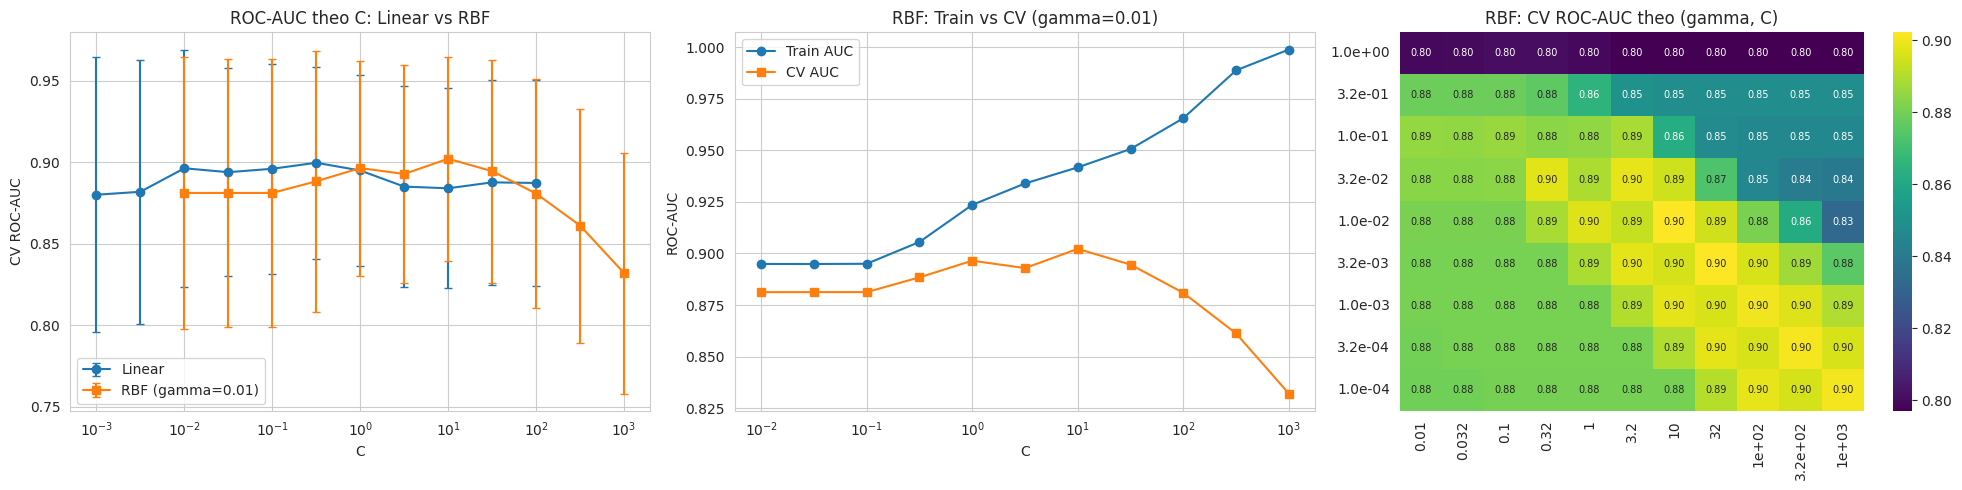

In [11]:
res_lin = pd.DataFrame(grid_lin.cv_results_)
res_rbf = pd.DataFrame(grid_rbf.cv_results_)
res_rbf["C"] = res_rbf["param_svc__C"].astype(float)
res_rbf["gamma"] = res_rbf["param_svc__gamma"].astype(float)
best_gamma = grid_rbf.best_params_["svc__gamma"]
sub = res_rbf[res_rbf["gamma"] == best_gamma].sort_values("C")

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# (a) AUC theo C
ax[0].errorbar(C_lin, res_lin["mean_test_score"], yerr=res_lin["std_test_score"], marker="o", capsize=3, label="Linear")
ax[0].errorbar(sub["C"], sub["mean_test_score"], yerr=sub["std_test_score"], marker="s", capsize=3, label=f"RBF (gamma={best_gamma:.4g})")
ax[0].set_xscale("log"); ax[0].set_xlabel("C"); ax[0].set_ylabel("CV ROC-AUC")
ax[0].set_title("ROC-AUC theo C: Linear vs RBF"); ax[0].legend()

# (b) Train vs CV của RBF (kiểm tra overfitting)
ax[1].plot(sub["C"], sub["mean_train_score"], "o-", label="Train AUC")
ax[1].plot(sub["C"], sub["mean_test_score"], "s-", label="CV AUC")
ax[1].set_xscale("log"); ax[1].set_xlabel("C"); ax[1].set_ylabel("ROC-AUC")
ax[1].set_title(f"RBF: Train vs CV (gamma={best_gamma:.4g})"); ax[1].legend()

# (c) Heatmap C x gamma
piv = res_rbf.pivot(index="gamma", columns="C", values="mean_test_score")
piv.index = [f"{g:.1e}" for g in piv.index]; piv.columns = [f"{c:.2g}" for c in piv.columns]
sns.heatmap(piv, annot=True, fmt=".2f", cmap="viridis", ax=ax[2], annot_kws={"size": 7})
ax[2].set_title("RBF: CV ROC-AUC theo (gamma, C)"); ax[2].invert_yaxis()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/svm_tuning.png", dpi=150)
plt.show()

## 6. So sánh Linear vs RBF với tham số tối ưu (5-Fold CV trên Train)

,Accuracy,Precision,Recall,F1,ROC_AUC
linear,0.8014 ± 0.0582,0.8075 ± 0.0768,0.7602 ± 0.1096,0.7767 ± 0.0649,0.8998 ± 0.0589
rbf,0.8225 ± 0.0720,0.8338 ± 0.0900,0.7784 ± 0.1101,0.7997 ± 0.0803,0.9022 ± 0.0625


,linear,rbf
Fold 1,0.9703,0.9755
Fold 2,0.9003,0.9038
Fold 3,0.8073,0.8073
Fold 4,0.9527,0.9618
Fold 5,0.8681,0.8626


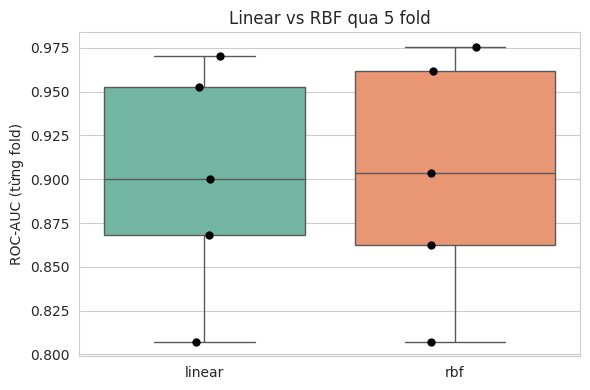

Kernel tốt nhất theo CV ROC-AUC: RBF | chênh lệch RBF - Linear = 0.0025


In [12]:
best_pipes = {"linear": clone(grid_lin.best_estimator_), "rbf": clone(grid_rbf.best_estimator_)}
cv_res, cv_raw = {}, {}
for k, p in best_pipes.items():
    cv_res[k], cv_raw[k] = cv_summary(p)

cmp_df = pd.DataFrame({k: {m: f"{v[m][0]:.4f} ± {v[m][1]:.4f}" for m in SCORING} for k, v in cv_res.items()}).T
display(cmp_df)

fold_auc = pd.DataFrame({k: cv_raw[k]["test_ROC_AUC"] for k in cv_raw}, index=[f"Fold {i+1}" for i in range(5)])
display(fold_auc.round(4))

plt.figure(figsize=(6, 4))
sns.boxplot(data=fold_auc, palette="Set2"); sns.stripplot(data=fold_auc, color="black", size=6)
plt.ylabel("ROC-AUC (từng fold)"); plt.title("Linear vs RBF qua 5 fold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/svm_fold_auc.png", dpi=150); plt.show()

best_kernel = max(cv_res, key=lambda k: cv_res[k]["ROC_AUC"][0])
print("Kernel tốt nhất theo CV ROC-AUC:", best_kernel.upper(),
      "| chênh lệch RBF - Linear =", round(cv_res["rbf"]["ROC_AUC"][0] - cv_res["linear"]["ROC_AUC"][0], 4))

## 7. Phân tích tính tuyến tính / phi tuyến
Chiếu dữ liệu (sau tiền xử lý) xuống **PCA 2D** chỉ để minh họa ranh giới quyết định của 2 kernel (không dùng để đánh giá mô hình).

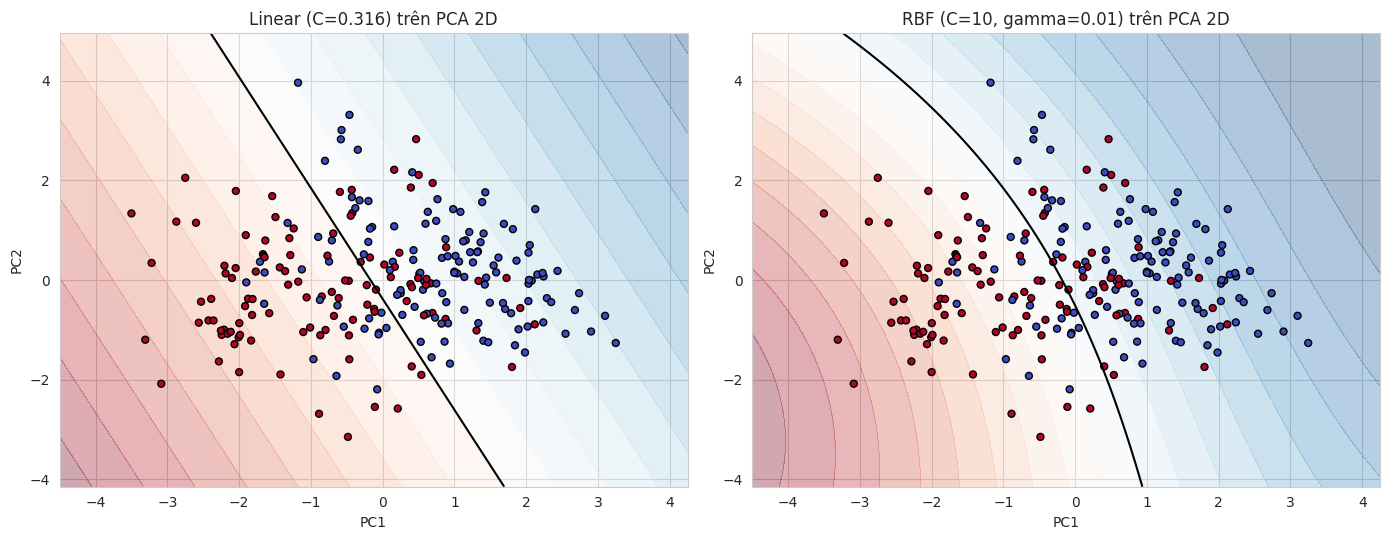

In [13]:
pre_vis = clone(best_pipes["linear"].named_steps["pre"]).fit(X_train)
Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(pre_vis.transform(X_train))

def boundary(ax, svc, title):
    svc.fit(Z, y_train)
    x_min, x_max = Z[:, 0].min() - 1, Z[:, 0].max() + 1
    y_min, y_max = Z[:, 1].min() - 1, Z[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    zz = svc.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.35)
    ax.contour(xx, yy, zz, levels=[0], colors="k", linewidths=1.5)
    ax.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

p_lin = {k.replace("svc__", ""): float(v) for k, v in grid_lin.best_params_.items()}
p_rbf = {k.replace("svc__", ""): float(v) for k, v in grid_rbf.best_params_.items()}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
boundary(ax[0], SVC(kernel="linear", random_state=RANDOM_STATE, **p_lin), f"Linear (C={p_lin['C']:.3g}) trên PCA 2D")
boundary(ax[1], SVC(kernel="rbf", random_state=RANDOM_STATE, **p_rbf), f"RBF (C={p_rbf['C']:.3g}, gamma={p_rbf['gamma']:.3g}) trên PCA 2D")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/svm_decision_boundary.png", dpi=150); plt.show()

In [14]:
d = cv_res["rbf"]["ROC_AUC"][0] - cv_res["linear"]["ROC_AUC"][0]
print(f"CV ROC-AUC  Linear = {cv_res['linear']['ROC_AUC'][0]:.4f} | RBF = {cv_res['rbf']['ROC_AUC'][0]:.4f} | chênh = {d:+.4f}")
if abs(d) < 0.01:
    print("-> Hai kernel gần như ngang nhau: dữ liệu có tính TUYẾN TÍNH đáng kể (RBF không mang lại lợi ích rõ rệt).")
elif d > 0:
    print("-> RBF vượt Linear: dữ liệu có thành phần PHI TUYẾN mà siêu phẳng tuyến tính chưa nắm bắt hết.")
else:
    print("-> Linear tốt hơn RBF: dữ liệu gần tách tuyến tính, RBF dễ bị overfit với số mẫu nhỏ.")

CV ROC-AUC  Linear = 0.8998 | RBF = 0.9022 | chênh = +0.0025
-> Hai kernel gần như ngang nhau: dữ liệu có tính TUYẾN TÍNH đáng kể (RBF không mang lại lợi ích rõ rệt).


## 8. Đánh giá cuối trên tập Test
Mô hình đã chọn bằng CV (không dùng Test để tune). Kết quả Test báo cáo **riêng**, không trộn với CV.

In [15]:
test_res = {}
for k, g in {"linear": grid_lin, "rbf": grid_rbf}.items():
    m = g.best_estimator_                       # đã refit trên toàn bộ Train
    score = m.decision_function(X_test)         # điểm quyết định cho lớp bệnh (=1)
    pred = m.predict(X_test)
    test_res[k] = {"y_pred": pred, "y_score": score,
                   "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                   "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                   "ROC_AUC": roc_auc_score(y_test, score)}

test_df = pd.DataFrame({k: {m: round(v[m], 4) for m in SCORING} for k, v in test_res.items()}).T
print("KẾT QUẢ TEST (riêng, không trộn với CV):")
display(test_df)

KẾT QUẢ TEST (riêng, không trộn với CV):


,Accuracy,Precision,Recall,F1,ROC_AUC
linear,0.8167,0.8696,0.7143,0.7843,0.9442
rbf,0.8167,0.8696,0.7143,0.7843,0.9308


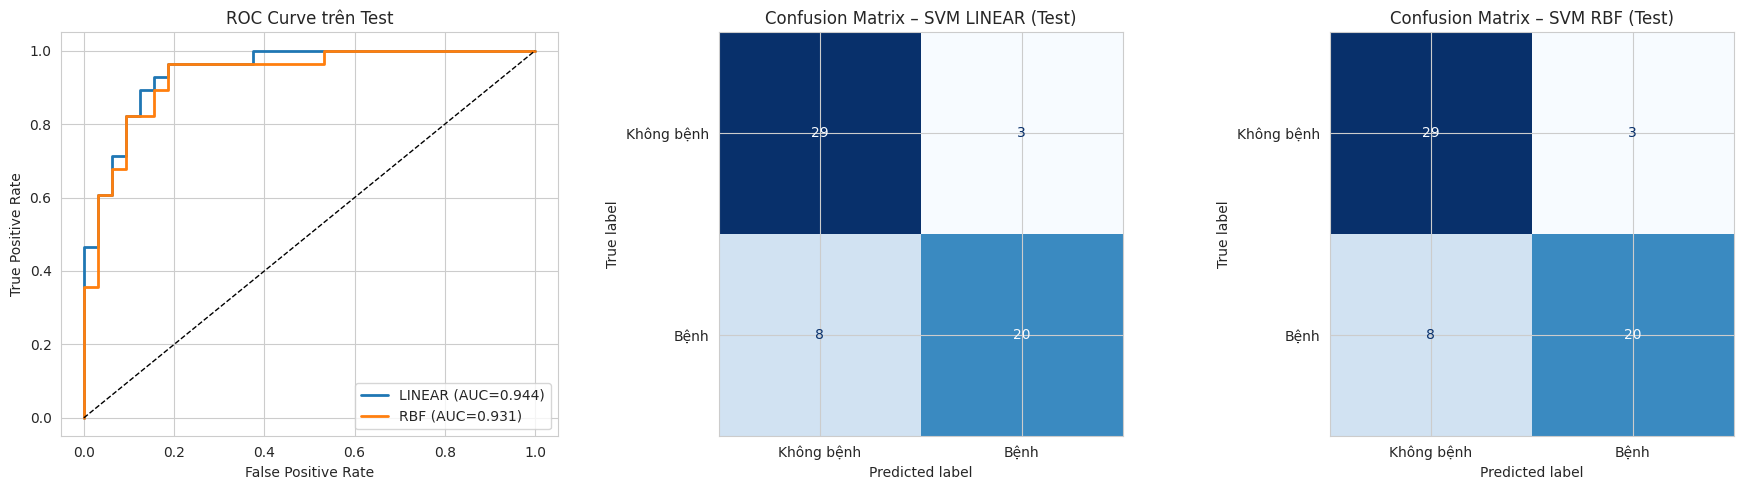

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# ROC cả hai kernel
for k, c in zip(["linear", "rbf"], ["tab:blue", "tab:orange"]):
    fpr, tpr, _ = roc_curve(y_test, test_res[k]["y_score"])
    ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{k.upper()} (AUC={test_res[k]['ROC_AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC Curve trên Test"); ax[0].legend(loc="lower right")

# Confusion matrix từng kernel
for a, k in zip(ax[1:], ["linear", "rbf"]):
    cm = confusion_matrix(y_test, test_res[k]["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=["Không bệnh", "Bệnh"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Confusion Matrix – SVM {k.upper()} (Test)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/svm_roc_confusion.png", dpi=150); plt.show()

## 9. Xuất dictionary kết quả và file cho TV5
`Model` là SVM với kernel tốt nhất theo CV ROC-AUC; kết quả kernel còn lại được ghi trong `Note`.
Các chỉ số `_mean`, `_std` lấy từ 5-Fold CV trên tập Train.

{
  "Model": "SVM (RBF)",
  "Accuracy_mean": 0.8225,
  "Accuracy_std": 0.072,
  "Precision_mean": 0.8338,
  "Recall_mean": 0.7784,
  "F1_mean": 0.7997,
  "ROC_AUC_mean": 0.9022,
  "Best_params": {
    "kernel": "rbf",
    "C": 10.0,
    "gamma": 0.01
  },
  "Note": "Chon kernel RBF theo CV ROC-AUC. LINEAR: CV ROC-AUC=0.8998 (params={'C': 0.31622776601683794}). Test: Acc=0.8167, AUC=0.9308. y_score = decision_function (lop benh=1)."
}


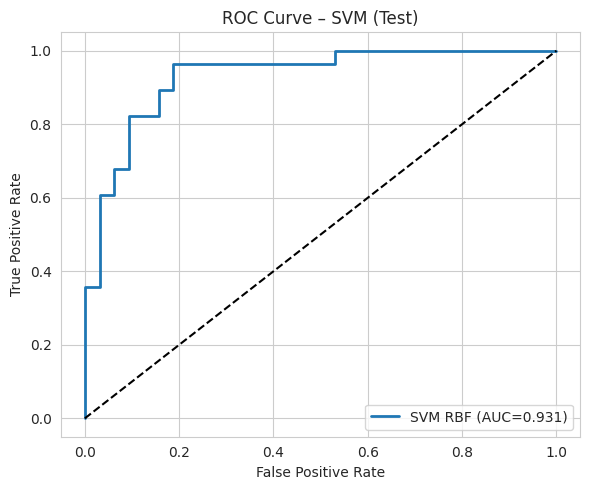

Đã lưu: ['svm_best_model.joblib', 'svm_decision_boundary.png', 'svm_eda.png', 'svm_fold_auc.png', 'svm_result.json', 'svm_roc.png', 'svm_roc_confusion.png', 'svm_tuning.png', 'y_pred_svm.npy', 'y_score_svm.npy']


In [17]:
other = "linear" if best_kernel == "rbf" else "rbf"
best_params = {"kernel": best_kernel, **(p_rbf if best_kernel == "rbf" else p_lin)}
s = cv_res[best_kernel]

svm_result = {
    "Model": f"SVM ({best_kernel.upper()})",
    "Accuracy_mean": round(float(s["Accuracy"][0]), 4),
    "Accuracy_std": round(float(s["Accuracy"][1]), 4),
    "Precision_mean": round(float(s["Precision"][0]), 4),
    "Recall_mean": round(float(s["Recall"][0]), 4),
    "F1_mean": round(float(s["F1"][0]), 4),
    "ROC_AUC_mean": round(float(s["ROC_AUC"][0]), 4),
    "Best_params": {k: (float(v) if not isinstance(v, str) else v) for k, v in best_params.items()},
    "Note": (f"Chon kernel {best_kernel.upper()} theo CV ROC-AUC. "
             f"{other.upper()}: CV ROC-AUC={cv_res[other]['ROC_AUC'][0]:.4f} "
             f"(params={p_lin if other=='linear' else p_rbf}). "
             f"Test: Acc={test_res[best_kernel]['Accuracy']:.4f}, AUC={test_res[best_kernel]['ROC_AUC']:.4f}. "
             f"y_score = decision_function (lop benh=1).")
}
print(json.dumps(svm_result, indent=2, ensure_ascii=False))

# Lưu file cho TV5
np.save(f"{OUT_DIR}/y_pred_svm.npy",  test_res[best_kernel]["y_pred"])
np.save(f"{OUT_DIR}/y_score_svm.npy", test_res[best_kernel]["y_score"])
with open(f"{OUT_DIR}/svm_result.json", "w", encoding="utf-8") as f:
    json.dump(svm_result, f, indent=2, ensure_ascii=False)
joblib.dump((grid_rbf if best_kernel == "rbf" else grid_lin).best_estimator_, f"{OUT_DIR}/svm_best_model.joblib")

# ROC riêng của mô hình SVM tốt nhất (sản phẩm bắt buộc)
fpr, tpr, _ = roc_curve(y_test, test_res[best_kernel]["y_score"])
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, lw=2, label=f"SVM {best_kernel.upper()} (AUC={test_res[best_kernel]['ROC_AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve – SVM (Test)"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/svm_roc.png", dpi=150); plt.show()

print("Đã lưu:", sorted(os.listdir(OUT_DIR)))

## 10. Checklist contract
- [x] `RANDOM_STATE = 42`, `StratifiedKFold(5, shuffle=True, random_state=42)`
- [x] Dùng `X_train_raw.csv`, `X_test_raw.csv`, `y_train.npy`, `y_test.npy`
- [x] Scaler / One-Hot nằm trong Pipeline, fit theo từng fold (không leakage)
- [x] Tune tối đa 2–3 tham số, chọn theo ROC-AUC
- [x] Không dùng Test để tune; kết quả Test báo riêng
- [x] Dictionary đúng format + `y_pred`, `y_score` (target = 1)
- [x] Chỉ dùng pandas, numpy, scikit-learn, matplotlib, seaborn, joblib